# When do CS & Engineering students finish for the day?

**Goal:** pick times for CSHub and GDG on Campus events when the most computing and engineering students have *finished their last class of the day* but haven't gone home yet.

Most students leave within about an hour of their last class. A lecture that ends with another class right after it doesn't free anyone, so what matters is when each student's **last** class of the day ends. This notebook works that out from two public York sources:

| Source | What it gives us |
|---|---|
| York course timetables, Fall/Winter 2026-27 (Lassonde `FW2026LE` + Science `FW2026SC`) | every section's day, time, room, and type (lecture, lab, tutorial) |
| Lassonde 2026-27 degree checklists + the Undergraduate Calendar (Data Science) | which courses each program requires, by year and term |

Sections 1–7 are about schedules only: for a typical student in a given program and year, when does their last required class of the day end? Section 8 then turns shares into **estimated numbers of people**, using OIPA's Fall 2025 headcounts (Keele only) and its first-year retention rate.

**Walkthrough**
1. The timetable dataset
2. Campus rhythm: when do classes let out?
3. Degree requirements and how much of them we can see
4. The model, shown on one student's week
5. One cohort in detail
6. Every cohort side by side
7. When the day ends, and the best event windows
8. Weighting by headcount: how many people are busy, and how many are free
9. Caveats and how to update

### Setup
Install the dependencies with `pip install -r requirements.txt`, then run this notebook from the repo root (the folder containing `data/` and `src/`).

In [2]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, FancyBboxPatch

ROOT = pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import campus_model as cm

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 60)

# Chart style: one blue ramp for magnitude, quiet axes, no chart junk
INK, INK2, RULE = "#1b1f24", "#5b6370", "#d9dde3"
BLUE, ORANGE = "#2a78d6", "#eb6834"
CMAP = LinearSegmentedColormap.from_list("ramp", ["#f4f6f9", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": RULE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "legend.frameon": False,
})

def heat(ax, grid, title, vmax=None, slots=slice(None), fmt=None, cbar_label=None):
    '''Day x time heatmap. grid is 5 x N_SLOTS (days x 30-min slots).'''
    g = np.asarray(grid)[:, slots]
    labels = np.array(cm.SLOT_LABELS)[slots]
    im = ax.imshow(g.T, aspect="auto", cmap=CMAP, vmin=0, vmax=vmax if vmax is not None else max(g.max(), 1e-9),
                   interpolation="nearest")
    ax.set_xticks(range(5), cm.DAYS)
    ax.xaxis.tick_top()
    ticks = [i for i, s in enumerate(labels) if s.endswith(":00")]
    ax.set_yticks(ticks, [labels[i] for i in ticks])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, pad=22)
    if fmt:
        for d in range(g.shape[0]):
            for t in range(g.shape[1]):
                v = g[d, t]
                if v >= (vmax or g.max()) * 0.08:
                    ax.text(d, t, fmt(v), ha="center", va="center", fontsize=7,
                            color="white" if v > (vmax or g.max()) * 0.55 else INK)
    return im

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

Matplotlib is building the font cache; this may take a moment.


## 1. The timetable dataset

`data/york_fw2026_meetings.csv` merges the Lassonde and Science timetables, **with everything taught at the Markham campus removed** (CSSD, Digital Technologies, and the Markham sections of first-year courses). **One row = one meeting of one section on one weekday.** EECS 2030 section E, for example, has a lecture on Monday and Wednesday (two rows) and five possible labs (five more rows, one per lab group).

Key columns: `course_code`, `section` (A, B, E…), `type` (LECT, LAB, TUTR, BLEN = blended), `meet` (lab or tutorial group number), `term` (F, W, Y = full year), `day`, `start`, `end`, `campus`, `room`. `cross_listed` flags meetings shared by two course codes in the same room and time.

In [3]:
raw = pd.read_csv(ROOT / "data/york_fw2026_meetings.csv", dtype=str).fillna("")
print(f"{len(raw):,} meeting rows · {raw.course_code.nunique():,} courses · faculties: {', '.join(sorted(raw.fac.unique()))}")
raw[(raw.course_code == "EECS 2030") & (raw.term == "F") & (raw.section == "E")][
    ["course_code", "section", "type", "meet", "day", "start", "end", "room"]]

4,236 meeting rows · 648 courses · faculties: LE, SC


,course_code,section,type,meet,day,start,end,room
518,EECS 2030,E,LECT,01,Mon,10:00,11:20,CLH G
519,EECS 2030,E,LECT,01,Wed,10:00,11:20,CLH G
520,EECS 2030,E,LAB,01,Wed,16:00,17:20,WSC 105
521,EECS 2030,E,LAB,02,Wed,16:00,17:20,WSC 106
522,EECS 2030,E,LAB,03,Wed,16:00,17:20,WSC 108


In [4]:
# What kinds of meetings are in there, and where?
(raw.assign(when=np.where(raw.start == "", "no fixed time", "timed"))
    .pivot_table(index="type", columns="campus", values="course", aggfunc="size", fill_value=0)
    .rename(columns={"": "(none)"})
    .sort_values("Keele", ascending=False).head(10))

campus,(none),Glendon,Keele,Seneca at York
type,,,,
LECT,24,10,1605,10
LAB,101,0,1529,0
TUTR,36,0,500,0
BLEN,16,0,163,0
WKSP,4,0,36,0
SEMR,2,0,16,0
ONCA,13,0,14,0
FDEX,8,0,7,0
ISTY,34,0,4,0


For everything below we keep **timed, in-person meetings Monday to Friday** and fold sub-terms (F1, F2, W3…) into plain Fall or Winter.

In [5]:
meetings = cm.load_meetings(ROOT / "data/york_fw2026_meetings.csv")
keele = meetings[meetings.campus == "Keele"]
print(f"{len(meetings):,} timed in-person meetings, {len(keele):,} of them at Keele")

3,880 timed in-person meetings, 3,860 of them at Keele


## 2. Campus rhythm: when do classes let out?

Before modelling any students, look at the raw timetable. Each cell counts **lectures ending** in that half-hour at Keele in the Fall term, deduplicated for cross-listing. A lecture counts once whether it has 20 seats or 300.

Computing = EECS, DIGT. Engineering = ENG, MECH, CIVL, ESSE, TRON. Math & physics = MATH, PHYS (these also serve students outside Lassonde).

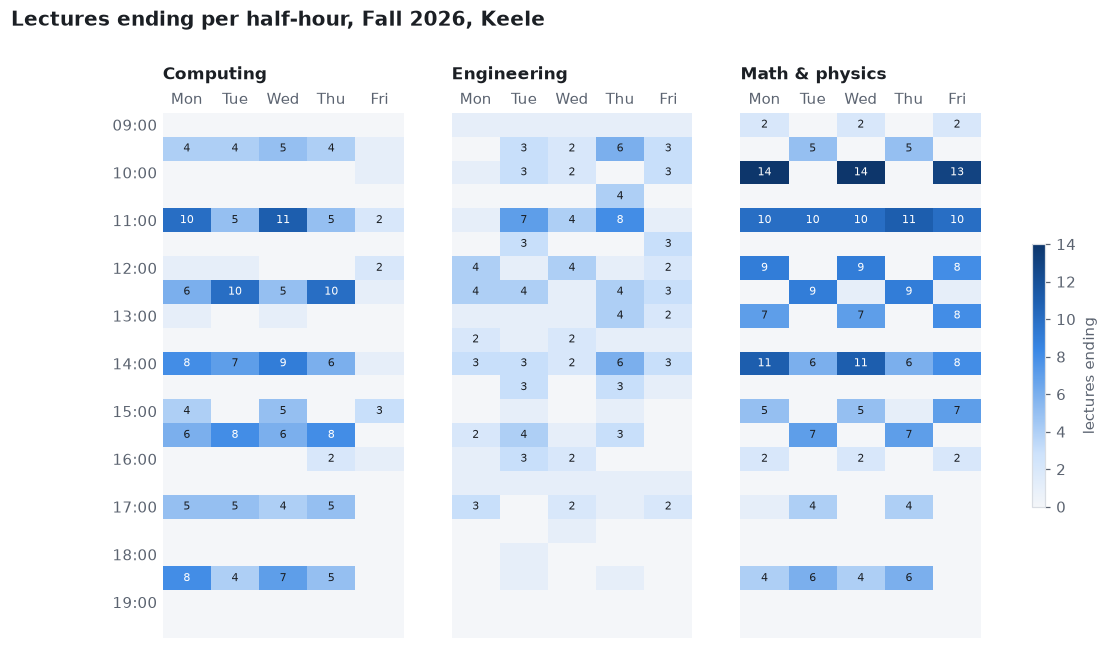

In [6]:
GROUPS = {
    "Computing": {"EECS", "DIGT"},
    "Engineering": {"ENG", "MECH", "CIVL", "ESSE", "TRON"},
    "Math & physics": {"MATH", "PHYS"},
}

def ending_grid(df):
    g = np.zeros((5, cm.N_SLOTS))
    lect = df[df.type.isin(cm.LECTURE_TYPES)].drop_duplicates(["term", "day", "start", "dur_min", "room"])
    for _, r in lect.iterrows():
        s = (r.end_m - cm.DAY_START) // cm.SLOT
        if 0 <= s < cm.N_SLOTS:
            g[cm.DAYS.index(r.day), s] += 1
    return g

fall_keele = keele[keele.term_fw.isin(["F", "Y"])]
grids = {k: ending_grid(fall_keele[fall_keele.dept.isin(v)]) for k, v in GROUPS.items()}
vmax = max(g.max() for g in grids.values())
fig, axes = plt.subplots(1, 3, figsize=(12, 6.2), sharey=True)
win = slice(2, 24)  # 09:00-19:30
for ax, (name, g) in zip(axes, grids.items()):
    im = heat(ax, g, name, vmax=vmax, slots=win, fmt=lambda v: f"{v:.0f}")
fig.suptitle("Lectures ending per half-hour, Fall 2026, Keele", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.colorbar(im, ax=axes, shrink=0.5, label="lectures ending")
save(fig, "1_lectures_ending"); plt.show()

**How to read it.** York runs on two block patterns: Monday/Wednesday/Friday lectures are 50 minutes (they end at :20), Tuesday/Thursday lectures are 80 minutes (they end at :50). That's why classes let out in waves rather than evenly. Friday is quiet across the board, and very little ends after 18:00.

**Careful:** this counts *every* lecture section ending, including parallel sections of the same course and lectures where students walk straight into another class. It counts meetings, not people. It shows the campus rhythm, not when people are free. Sections 4–7 fix that by following each simulated student's day to their **last** class.

## 3. Degree requirements

`data/requirements_all.csv` was parsed from the Lassonde 2026-27 degree checklists (`src/parse_checklists.py`), plus Data Science (Undergraduate Calendar, entered by hand). Markham-only programs (CSSD) are left out. **One row = one course that can fill a requirement slot.**

* `kind = required`: the slot names one course.
* `kind = choice`: the slot names alternatives ("EECS 1012 or EECS 1015"); the model picks one at random.
* `term_hint` is the checklist's recommended term: F, W, Y, "F or W", or "Any".
* Elective pools ("6 credits from this list") and general-education placeholders are left out, because they don't pin a student to a time.

In [7]:
req = pd.read_csv(ROOT / "data/requirements_all.csv")
req.groupby("program").agg(
    years=("year", lambda y: ", ".join(map(str, sorted(y.unique())))),
    slots=("slot", "nunique"),
    courses=("course_code", "nunique"),
).sort_index()

,years,slots,courses
program,,,
Bachelor of Arts (BA) Computer Science,"1, 2, 3",16,20
Bachelor of Arts (BA) Digital Media,"1, 2, 3",13,15
Bachelor of Arts (BA) Honours Computer Science,"1, 2, 3",18,22
Bachelor of Arts (BA) Specialized Honours Computer Science,"1, 2, 3, 4",20,27
Bachelor of Arts (BA) Specialized Honours Computer Science (Software Development),"1, 2, 3, 4",26,31
Bachelor of Arts (BA) Specialized Honours Cybersecurity,"1, 2, 3, 4",30,32
Bachelor of Arts (BA) Specialized Honours Digital Media - Digital Media Arts,"1, 2, 3, 4",15,15
Bachelor of Arts (BA) Specialized Honours Digital Media - Digital Media Development,"1, 2, 3, 4",17,18
Bachelor of Arts (BA) Specialized Honours Digital Media - Digital Media Game Arts,"1, 2, 3, 4",18,18


### How much of each program can we see?

A required course only helps if it's in one of our two timetables. Courses from other faculties (Digital Media's DATT courses in AMPD; ITEC, WRIT and PHIL in LA&PS; Schulich courses in the Data Science business stream) are missing, so those programs look lighter than they are. A few 4th-year courses also aren't offered this year.

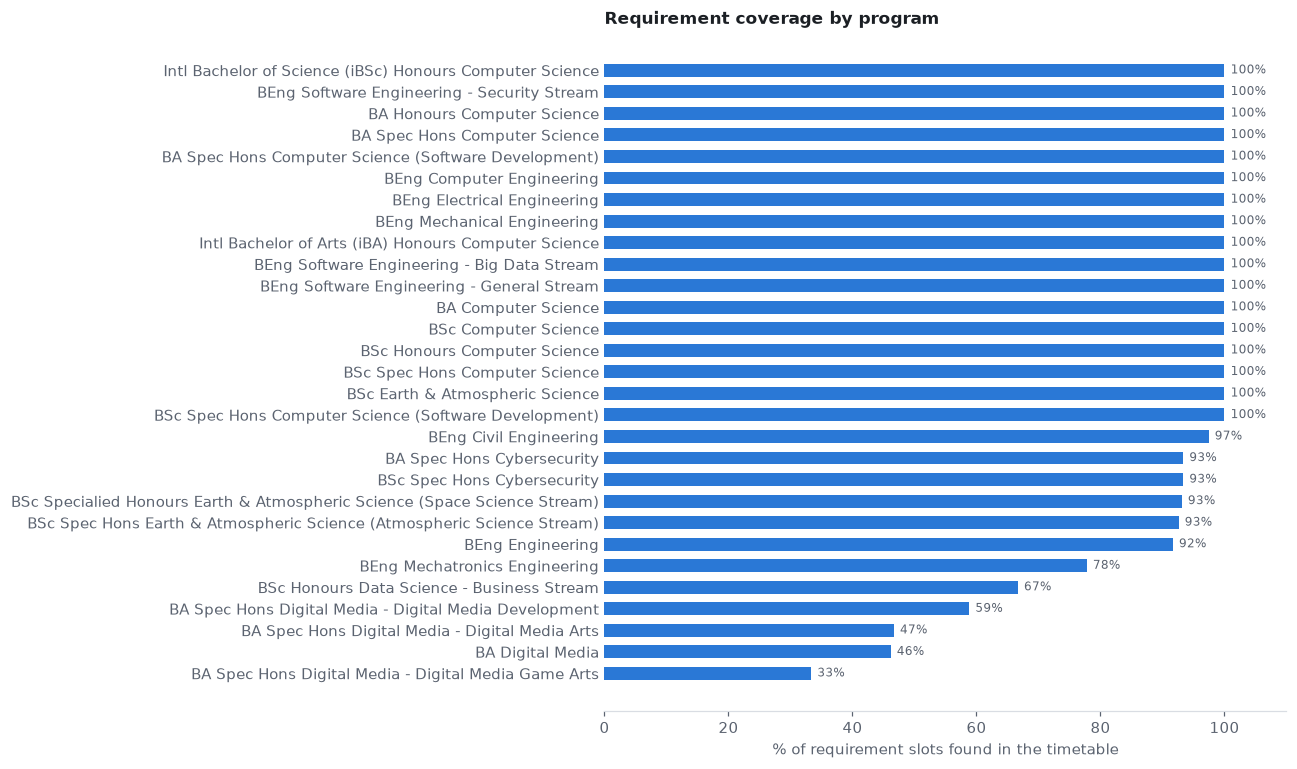

In [8]:
have = set(meetings.course_code)
cov = (req.assign(found=req.course_code.isin(have))
          .groupby(["program", "slot"]).found.any()            # a slot is covered if any option is in the timetable
          .groupby("program").mean().sort_values())
short = lambda p: (p.replace("Bachelor of Engineering (BEng) Specialized Honours ", "BEng ")
                     .replace("Bachelor of Science (BSc) ", "BSc ").replace("Bachelor of Arts (BA) ", "BA ")
                     .replace("International ", "Intl ").replace("Specialized Honours", "Spec Hons")
                     .replace("Honours Bachelor of Applied Science (BASc)", "BASc Hons"))
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh([short(p) for p in cov.index], cov.values * 100, color=BLUE, height=0.6)
for i, v in enumerate(cov.values):
    ax.text(v * 100 + 1, i, f"{v:.0%}", va="center", fontsize=8, color=INK2)
ax.set_xlim(0, 110); ax.set_xlabel("% of requirement slots found in the timetable")
ax.set_title("Requirement coverage by program")
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
save(fig, "2_requirement_coverage"); plt.show()

## 4. The model, on one student's week

For a program and year, the model builds a plausible required-course timetable:

1. **Pick the term.** "F" courses go in Fall, "W" in Winter. "F or W" courses go in whichever term the timetable offers them; if both, it's a coin flip.
2. **Pick among alternatives** for choice slots.
3. **Pick one section.** Each student takes exactly **one** section of each course and one lab or tutorial group per type, so a course with 8 parallel sections (MATH 1013 has 8 this Fall) never counts a student 8 times. Every section is equally likely. Engineering students only get EECS sections E, F, G, H, I, V, X, Y, Z (the checklists reserve those for BEng students); everyone else gets the other EECS sections.
4. **Pick a lab or tutorial group** inside that section, again equally likely.
5. **Avoid clashes**, like a real student registering. Courses are placed in a random order and each takes a section that doesn't overlap what's already chosen. If a clash can't be avoided, the student starts over (new order, new "F or W" term choices), up to 25 times.
6. **Add a 10-minute buffer.** Every class counts as ending 10 minutes late, for overruns, packing up and walking to wherever an event is: a class that ends at 17:20 frees students at 17:30.
7. **Find the last class of each day.** That's the end of the latest required meeting that day, whether lecture, lab or tutorial: a lab after a lecture means the day isn't over.
8. **Free on campus** = on campus and not in class: between classes, or within 60 minutes after the last class. **Done for the day** is the second part only: the student is still around with nothing left to go to. A lecture followed by another class makes the student free for the gap, but not done.

Repeat that 400 times per cohort and you get shares: e.g. "in this half-hour, 35% of 2nd-year Software Engineering students have finished their last class and are still around."

Here is one sampled week for a 2nd-year Software Engineering student (General stream), Fall term. The dashed line marks when each day's last class ends.

,course_code,section,type,meet,day,start,end,room
518,EECS 2030,E,LECT,01,Mon,10:00,11:20,CLH G
564,EECS 2032,E,LAB,01,Mon,12:30,14:20,LAS 1006
1478,ENG 2003,Z,SEMR,01,Mon,14:30,17:20,
1452,ENG 2001,A,BLEN,01,Tue,08:30,11:20,SLH D
562,EECS 2032,E,LECT,01,Tue,14:30,15:50,SLH F
595,EECS 2200,F,LECT,01,Tue,16:00,17:20,LSB 103
3312,MATH 1090,C,LECT,01,Tue,17:30,18:50,DB 0001
519,EECS 2030,E,LECT,01,Wed,10:00,11:20,CLH G
598,EECS 2200,F,LAB,02,Wed,13:00,15:50,BRG 334
520,EECS 2030,E,LAB,01,Wed,16:00,17:20,WSC 105


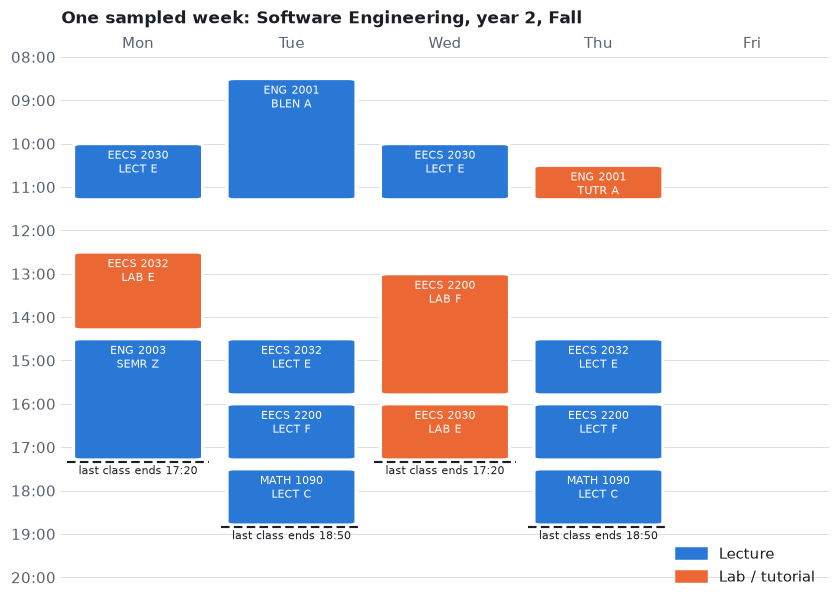

In [9]:
SE = "Bachelor of Engineering (BEng) Specialized Honours Software Engineering - General Stream"
CACHE = {}
week = cm.sample_student(meetings, req, SE, 2, "F", seed=3, option_cache=CACHE)
display(week.drop(columns=["start_m", "end_m"]).sort_values(["day", "start"], key=lambda s: s.map(cm.DAYS.index) if s.name == "day" else s))

fig, ax = plt.subplots(figsize=(9, 6.4))
for _, r in week.iterrows():
    d = cm.DAYS.index(r.day)
    color = BLUE if r.type in cm.LECTURE_TYPES else ORANGE
    ax.add_patch(FancyBboxPatch((d - 0.42, r.start_m / 60), 0.84, (r.end_m - r.start_m) / 60 - 0.04,
                                boxstyle="round,pad=0,rounding_size=0.05", fc=color, ec="white", lw=2))
    ax.text(d, r.start_m / 60 + 0.12, f"{r.course_code}\n{r.type} {r.section}", ha="center", va="top", fontsize=7.5, color="white")
for d, day in enumerate(cm.DAYS):
    ends = week.loc[week.day == day, "end_m"]
    if len(ends):
        e = ends.max() / 60
        ax.plot([d - 0.46, d + 0.46], [e, e], color=INK, lw=1.4, ls=(0, (4, 2)))
        ax.text(d, e + 0.08, f"last class ends {int(e):02d}:{round(e % 1 * 60):02d}", ha="center", va="top", fontsize=7.5, color=INK)
ax.set_xlim(-0.5, 4.5); ax.set_ylim(20.5, 8)
ax.set_xticks(range(5), cm.DAYS); ax.xaxis.tick_top()
ax.set_yticks(range(8, 21), [f"{h:02d}:00" for h in range(8, 21)])
ax.grid(axis="y", color=RULE, lw=0.6); ax.set_axisbelow(True)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.legend(handles=[Patch(color=BLUE, label="Lecture"), Patch(color=ORANGE, label="Lab / tutorial")], loc="lower right")
ax.set_title("One sampled week: Software Engineering, year 2, Fall", pad=22)
save(fig, "3_sample_week"); plt.show()

## 5. One cohort in detail

Same cohort, now 400 simulated students. Three views:

* **In a required class**: where the week's class time sits.
* **Last class of the day ends here**: the share of students whose final class that day ends in this half-hour. Each column adds up to everyone who has class that day.
* **Done for the day, still on campus**: the event audience.

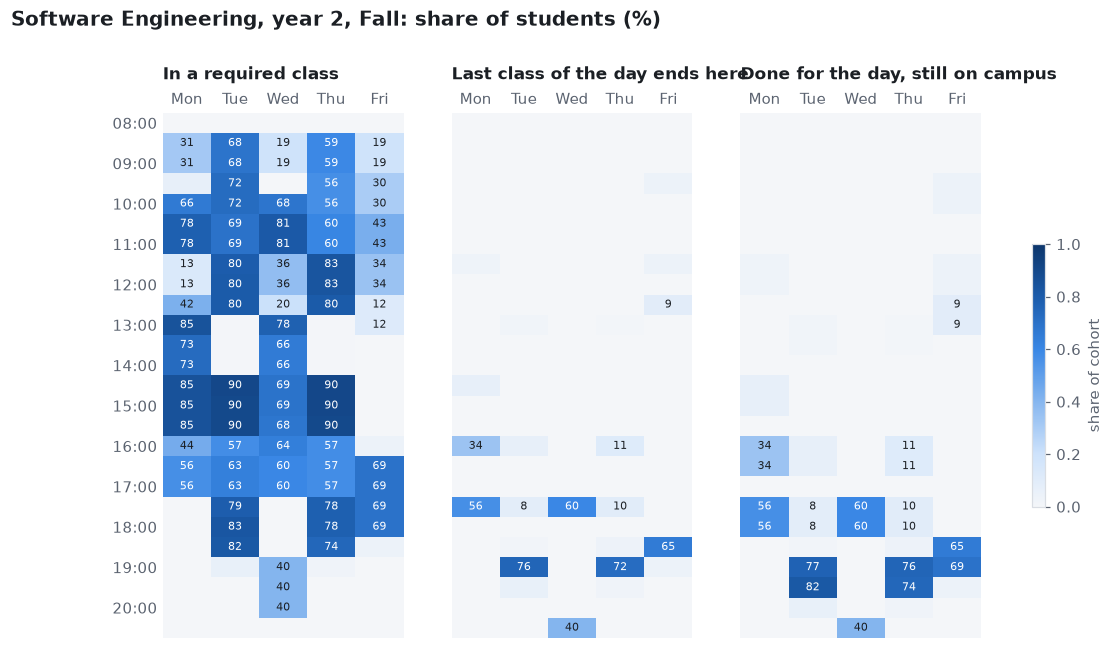

No required class that day: Mon 0%, Tue 0%, Wed 0%, Thu 0%, Fri 13%


In [10]:
one = cm.simulate_cohort(meetings, req, SE, 2, "F", n=400, option_cache=CACHE)
fig, axes = plt.subplots(1, 3, figsize=(12, 6.2), sharey=True)
win = slice(0, 26)  # 08:00-20:30
panels = [("in_class", "In a required class"), ("last_end", "Last class of the day ends here"),
          ("done", "Done for the day, still on campus")]
for ax, (k, t) in zip(axes, panels):
    im = heat(ax, one[k], t, vmax=1, slots=win, fmt=lambda v: f"{v*100:.0f}")
fig.suptitle("Software Engineering, year 2, Fall: share of students (%)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.colorbar(im, ax=axes, shrink=0.5, label="share of cohort")
save(fig, "4_cohort_detail_SE_Y2"); plt.show()
print("No required class that day:", ", ".join(f"{d} {v:.0%}" for d, v in zip(cm.DAYS, one["no_class"])))

## 6. Every cohort side by side

Now all the programs CSHub and GDG care most about, one row per program-year. Columns run Monday to Friday, 11:00 to 20:00. Each cell is the share of that cohort **done for the day and still on campus**.

CS is shown once: the BA and BSc Specialized Honours CS degrees list the same required courses, so they'd be identical rows.

Rows marked *thin* have under 6 hours a week of required classes we can see: mostly-elective years (upper-year CS, Data Science) or courses outside our timetables. Their numbers say little, so they're dropped from the combined view in section 7.

In [11]:
FOCUS = {
    "1st-year Engineering": "Bachelor of Engineering (BEng) Specialized Honours Engineering",
    "Software Eng":         SE,
    "Computer Eng":         "Bachelor of Engineering (BEng) Specialized Honours Computer Engineering",
    "Electrical Eng":       "Bachelor of Engineering (BEng) Specialized Honours Electrical Engineering",
    "Mechatronics Eng":     "Bachelor of Engineering (BEng) Specialized Honours Mechatronics Engineering",
    "Mechanical Eng":       "Bachelor of Engineering (BEng) Specialized Honours Mechanical Engineering",
    "Civil Eng":            "Bachelor of Engineering (BEng) Specialized Honours Civil Engineering",
    "CS (BSc Spec Hons)":   "Bachelor of Science (BSc) Specialized Honours Computer Science",
    "Cybersecurity (BSc)":  "Bachelor of Science (BSc) Specialized Honours Cybersecurity",
    "Digital Media Dev":    "Bachelor of Arts (BA) Specialized Honours Digital Media - Digital Media Development",
    "Data Science (BSc)":   "Bachelor of Science (BSc) Honours Data Science - Business Stream",
}
TERM = "F"
THIN_HOURS = 6   # cohorts with less visible required class time than this are flagged
results = []
for name, prog in FOCUS.items():
    for y in sorted(req.loc[req.program == prog, "year"].unique()):
        # BEng programs share the common first year; "1st-year Engineering" already covers it
        if cm.is_engineering(prog) and name != "1st-year Engineering" and y == 1:
            continue
        out = cm.simulate_cohort(meetings, req, prog, int(y), TERM, n=400, option_cache=CACHE)
        hours = out["in_class"].sum() * cm.SLOT / 60
        results.append(dict(cohort=f"{name} · Y{y}", program=name, year=int(y), hours=hours, **out))
res = pd.DataFrame(results)
res["thin"] = res.hours < THIN_HOURS
res[["cohort", "hours", "thin"]].assign(hours=lambda d: d.hours.round(1)).rename(columns={"hours": "required class-hours / week"})

,cohort,required class-hours / week,thin
0,1st-year Engineering · Y1,23.6,False
1,Software Eng · Y2,26.4,False
2,Software Eng · Y3,12.5,False
3,Software Eng · Y4,18.0,False
4,Computer Eng · Y2,22.4,False
5,Computer Eng · Y3,16.9,False
6,Computer Eng · Y4,9.2,False
7,Electrical Eng · Y2,20.3,False
8,Electrical Eng · Y3,12.8,False
9,Electrical Eng · Y4,3.0,True


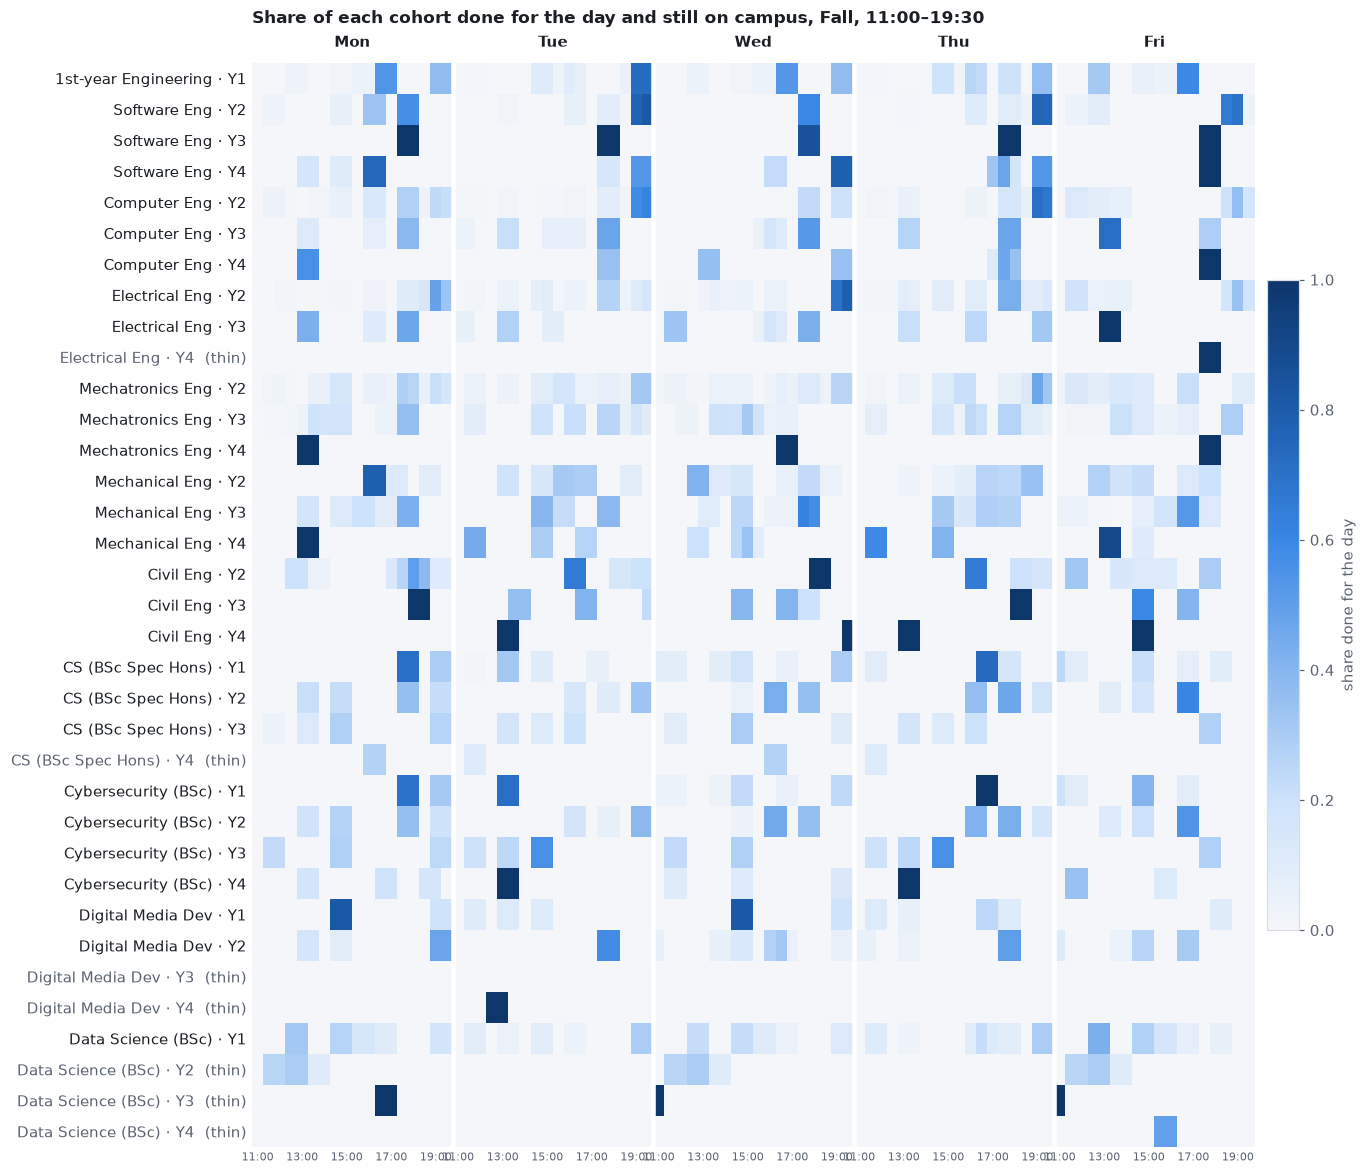

In [12]:
win = slice(6, 24)  # 11:00-19:30
labels = np.array(cm.SLOT_LABELS)[win]
M = np.stack([np.concatenate([r.done[d, win] for d in range(5)]) for r in res.itertuples()])
fig, ax = plt.subplots(figsize=(14, 0.32 * len(res) + 1.6))
im = ax.imshow(M, aspect="auto", cmap=CMAP, vmin=0, vmax=1, interpolation="nearest")
n = len(labels)
for d in range(1, 5):
    ax.axvline(d * n - 0.5, color="white", lw=3)
ax.set_xticks([d * n + i for d in range(5) for i in range(0, n, 4)],
              [labels[i] for d in range(5) for i in range(0, n, 4)], fontsize=7)   # times along the bottom
for d, day in enumerate(cm.DAYS):                                                   # days along the top
    ax.text(d * n + n / 2 - 0.5, -0.9, day, ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.tick_params(length=0)
ax.set_yticks(range(len(res)), [c + ("  (thin)" if t else "") for c, t in zip(res.cohort, res.thin)])
for lab, t in zip(ax.get_yticklabels(), res.thin):
    lab.set_color(INK2 if t else INK)
[s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Share of each cohort done for the day and still on campus, Fall, 11:00–19:30", pad=26)
fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01, label="share done for the day")
save(fig, "5_all_cohorts_done"); plt.show()

## 7. When does the day end, and the best event windows

Average across all non-thin cohorts. Each cohort counts equally (no headcount weighting yet), so read this as *how many of our cohorts have a big chunk of students finishing for the day*.

Left: when the last class of the day ends. Right: the share done for the day and still around, which is what an event can draw on.

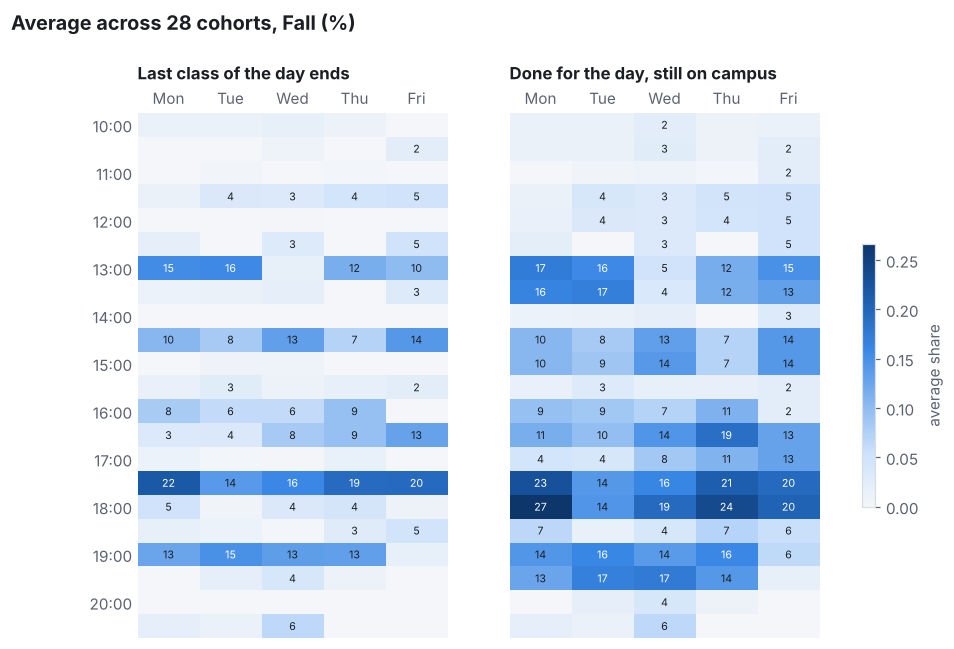

In [ ]:
use = res[~res.thin]
avg = lambda k: np.mean(np.stack(use[k].to_list()), axis=0)
last_avg, done_avg = avg("last_end"), avg("done")

fig, axes = plt.subplots(1, 2, figsize=(10, 6.2), sharey=True)
win = slice(4, 26)  # 10:00-20:30
heat(axes[0], last_avg, "Last class of the day ends", vmax=max(last_avg.max(), done_avg.max()), slots=win, fmt=lambda v: f"{v*100:.0f}")
im = heat(axes[1], done_avg, "Done for the day, still on campus", vmax=max(last_avg.max(), done_avg.max()), slots=win, fmt=lambda v: f"{v*100:.0f}")
fig.suptitle(f"Average across {len(use)} cohorts, Fall (%)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.colorbar(im, ax=axes, shrink=0.5, label="average share")
save(fig, "6_day_end_and_done"); plt.show()

The same thing as a cumulative curve: by each time of day, what share of cohorts has finished classes for the day? (Students with no required class that day are left out.) The steep steps are the moments big groups head home.

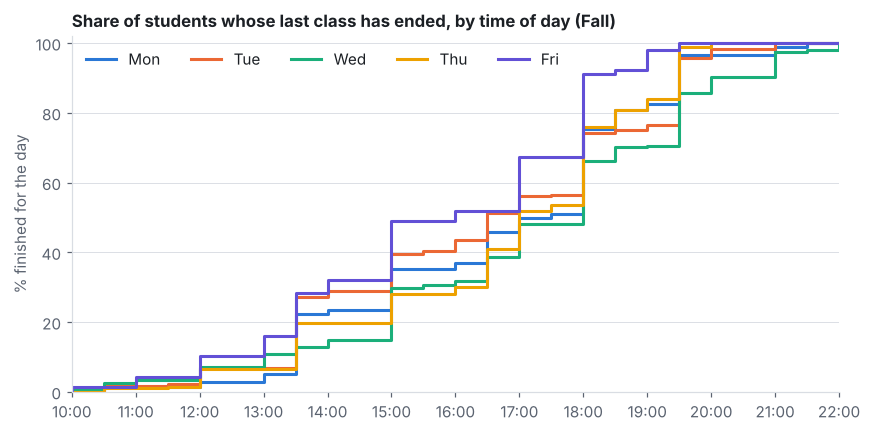

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(cm.N_SLOTS)
colors = [BLUE, ORANGE, "#1baf7a", "#eda100", "#6250d6"]
for d, (day, c) in enumerate(zip(cm.DAYS, colors)):
    has_class = last_avg[d].sum()
    cum = np.cumsum(last_avg[d]) / has_class if has_class else np.zeros_like(x, dtype=float)
    ax.plot(x + 1, cum * 100, color=c, lw=2, label=day, drawstyle="steps-post")
ax.set_xticks(range(0, cm.N_SLOTS + 1, 2), [f"{(cm.DAY_START + i * cm.SLOT) // 60:02d}:00" for i in range(0, cm.N_SLOTS + 1, 2)])
ax.set_xlim(4, 28); ax.set_ylim(0, 102)
ax.set_ylabel("% finished for the day")
ax.grid(axis="y", color=RULE, lw=0.6); ax.set_axisbelow(True)
ax.legend(ncol=5, loc="upper left")
ax.set_title("Share of students whose last class has ended, by time of day (Fall)")
save(fig, "7_cumulative_day_end"); plt.show()

### Ranked windows

Each half-hour from 11:00 to 19:30, ranked by the share of students **done for the day and still on campus**. "Just finished" is the share whose last class ended in the half-hour right before, the freshest part of the audience.

In [ ]:
def rank_windows(first_slot, last_slot, top=12):
    rows = []
    for d, day in enumerate(cm.DAYS):
        for s in range(first_slot, last_slot):
            start = cm.SLOT_LABELS[s]
            end = cm.SLOT_LABELS[s + 1] if s + 1 < cm.N_SLOTS else "22:00"
            best3 = use.assign(v=use.done.map(lambda g: g[d, s])).nlargest(3, "v")
            rows.append(dict(day=day, window=f"{start}–{end}", done_for_day=done_avg[d, s],
                             just_finished=last_avg[d, s - 1], most_done=", ".join(best3.cohort)))
    out = pd.DataFrame(rows).sort_values("done_for_day", ascending=False).head(top).reset_index(drop=True)
    out.index += 1
    return out.style.format({"done_for_day": "{:.0%}", "just_finished": "{:.0%}"}).bar(
        subset=["done_for_day"], color="#cde2fb", vmin=0, vmax=1)

rank_windows(6, 24)

,day,window,done_for_day,just_finished,most_done
1,Mon,18:00–18:30,27%,22%,"Software Eng · Y3, Civil Eng · Y3, CS (BSc Spec Hons) · Y1"
2,Thu,18:00–18:30,24%,19%,"Software Eng · Y3, Civil Eng · Y3, Digital Media Dev · Y2"
3,Mon,17:30–18:00,23%,1%,"Software Eng · Y3, CS (BSc Spec Hons) · Y1, Cybersecurity (BSc) · Y1"
4,Thu,17:30–18:00,21%,2%,"Software Eng · Y3, Digital Media Dev · Y2, Software Eng · Y4"
5,Fri,18:00–18:30,20%,20%,"Software Eng · Y3, Software Eng · Y4, Computer Eng · Y4"
6,Fri,17:30–18:00,20%,0%,"Software Eng · Y3, Software Eng · Y4, Computer Eng · Y4"
7,Wed,18:00–18:30,19%,16%,"Civil Eng · Y2, Software Eng · Y3, Software Eng · Y2"
8,Thu,16:30–17:00,19%,9%,"Cybersecurity (BSc) · Y1, CS (BSc Spec Hons) · Y1, Civil Eng · Y2"
9,Wed,19:30–20:00,17%,13%,"Civil Eng · Y4, Electrical Eng · Y2, Software Eng · Y4"
10,Mon,13:00–13:30,17%,2%,"Mechatronics Eng · Y4, Mechanical Eng · Y4, Computer Eng · Y4"


**Using this.** The top windows are when the biggest share of students has nothing left that day but hasn't left yet. Start an event at the beginning of one of these windows: most of the audience finished in the previous half-hour or two. The model assumes students stay about an hour after their last class, so an event starting more than an hour after a big release has mostly lost that crowd.

Change `TERM = "W"` in section 6 and re-run to get the Winter version.

## 8. Weighting by headcount: how many people are busy, and how many are free

Sections 5–7 count every cohort equally. Here each cohort is scaled by an **estimated number of students**.

**Headcounts** come from OIPA's Undergraduate Student Headcount dashboard, Fall 2025-26, **Keele-Glendon campus only** (`data/headcount_keele_fall2025.csv`). OIPA gives students per program, not per year, so we split each program across years.

**Retention** comes from OIPA's Undergraduate Retention Rate dashboard. It only has a university-wide figure: **89.9%** of the 2024 entering cohort returned for Year 2, a 10.1% loss. The assumptions:

* Year 2 → 3 loss is **half** the Year 1 → 2 loss (5.05%). This follows AIR's study of 17 US four-year institutions, where 23% of the 2015–16 entering cohort left after Year 1 and another 10% ("about half as many") after Year 2 ([Pitcher & Parsons, 2023, *More to the Retention Story*](https://www.air.org/sites/default/files/2023-08/AIR-More-to-the-Retention-Story-July-2023-Final.pdf)).
* No further loss after Year 3. (AIR found a small further loss, about 3% of the cohort, between Years 3 and 4; it is ignored here.)

So for every 100 students who start, about 89.9 reach Year 2 and 84.8 reach Years 3 and 4. A program's headcount is split across its years in those proportions.

Program-specific notes:

* **BEng majors** (Software, Computer, Electrical…) only hold Years 2–4. Year 1 is the undeclared "Engineering" program (728 students).
* **Mechatronics** is new: its 46 students are all treated as Year 2.
* **Data Science** started in 2023: Years 1–3 only.
* **CS** (2,093, all CS degrees) uses the BSc Specialized Honours requirements. **Digital Media** (all streams) uses the Development stream's.

In [ ]:
hc = pd.read_csv(ROOT / "data/headcount_keele_fall2025.csv")
RET_1_2 = 0.899                       # OIPA, 2024 cohort, Year 1 Fall -> Year 2 Fall
LOSS_1_2 = 1 - RET_1_2
LOSS_2_3 = LOSS_1_2 / 2               # assumption: half the first-year loss (AIR, Pitcher & Parsons 2023)
SURVIVE = {1: 1.0, 2: RET_1_2, 3: RET_1_2 - LOSS_2_3, 4: RET_1_2 - LOSS_2_3}   # no loss after year 3

COHORT_SOURCE = {   # notebook cohort -> (OIPA program, years that program holds)
    "1st-year Engineering": ("Engineering", [1]),
    "Software Eng":         ("Software Engineering", [2, 3, 4]),
    "Computer Eng":         ("Computer Engineering", [2, 3, 4]),
    "Electrical Eng":       ("Electrical Engineering", [2, 3, 4]),
    "Mechatronics Eng":     ("Mechatronics", [2]),
    "Mechanical Eng":       ("Mechanical Engineering", [2, 3, 4]),
    "Civil Eng":            ("Civil Engineering", [2, 3, 4]),
    "CS (BSc Spec Hons)":   ("Computer Science", [1, 2, 3, 4]),
    "Cybersecurity (BSc)":  ("Computer Security", [1, 2, 3, 4]),
    "Digital Media Dev":    ("Digital Media", [1, 2, 3, 4]),
    "Data Science (BSc)":   ("Data Science", [1, 2, 3]),
}

def students(program_name, year):
    src, years = COHORT_SOURCE[program_name]
    if year not in years:
        return 0.0
    total = hc.loc[hc.program == src, "headcount_fall2025"].item()
    return total * SURVIVE[year] / sum(SURVIVE[y] for y in years)

res["students"] = [students(p, y) for p, y in zip(res.program, res.year)]
print(f"Students covered by the model: {res.students.sum():,.0f} "
      f"(of whom {res.loc[res.thin, 'students'].sum():,.0f} are in thin cohorts with little visible required class time)")
(res[["cohort", "students", "hours", "thin"]]
   .assign(students=lambda d: d.students.round().astype(int), hours=lambda d: d.hours.round(1))
   .rename(columns={"students": "est. students", "hours": "required class-h / wk"}))

Students covered by the model: 5,105 (of whom 771 are in thin cohorts with little visible required class time)


,cohort,est. students,required class-h / wk,thin
0,1st-year Engineering · Y1,728,23.6,False
1,Software Eng · Y2,113,26.4,False
2,Software Eng · Y3,107,12.5,False
3,Software Eng · Y4,107,18.0,False
4,Computer Eng · Y2,106,22.4,False
5,Computer Eng · Y3,100,16.9,False
6,Computer Eng · Y4,100,9.2,False
7,Electrical Eng · Y2,88,20.3,False
8,Electrical Eng · Y3,83,12.8,False
9,Electrical Eng · Y4,83,3.0,True


### In class, free, done for the day, and gone, in people

Each cell is an **estimated number of students**, adding up all cohorts:

* **In class (busy)**: in a required class during that half-hour.
* **Free on campus**: on campus and not in class. Either between classes (they have another class later) or within an hour after their last class. This is everyone who could drop by.
* **Done for the day, still on campus**: the part of "free on campus" that has finished their last class within the past hour. They can stay for a whole event.
* **Not on campus**: not arrived yet, already gone home (more than an hour after their last class), or no required class that day. In class + free + not on campus always adds up to all students. In the late afternoon it is almost entirely people who already left or never came.

**The charts are interactive: hover over any cell** to see how many students from each program and year are in that state, both as a number and as a share of that group's enrolment. The cell total is also shown as a share of all students enrolled. Each chart is also saved as a standalone page in `figures/interactive_people_60min.html` (and `_30min`) that opens in any browser.

Partly-filled half-hours count proportionally (a class ending at 17:20 makes that half-hour two-thirds busy).

All cohorts are included here, thin ones too. Their students exist; we just can't see much of their week, so the busy counts are a floor.

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab, VS Code and classic Jupyter

MEASURES = [("in_class", "In class (busy)"), ("free", "Free on campus"),
            ("done", "Done for the day, still on campus"), ("away", "Not on campus")]
PLOTLY_SCALE = [[0, "#f4f6f9"], [0.2, "#cde2fb"], [0.4, "#86b6ef"], [0.6, "#3987e5"], [0.8, "#1c5cab"], [1, "#0d366b"]]
WIN = list(range(1, cm.N_SLOTS))                  # 08:30-22:00
TOTAL = res.students.sum()
slot_end = lambda s: cm.SLOT_LABELS[s + 1] if s + 1 < cm.N_SLOTS else "22:00"

def cohort_stacks(linger):
    # Per-cohort grids in people for each measure: arrays shaped (cohorts, days, slots)
    keys = [k for k, _ in MEASURES] + ["last_end"]
    stacks = {k: [] for k in keys}
    for _, r in res.iterrows():
        o = r if linger == 60 else cm.simulate_cohort(meetings, req, FOCUS[r.program], r.year, TERM,
                                                      n=400, linger=linger, option_cache=CACHE)
        for k in keys:
            stacks[k].append(np.asarray(o[k]) * r.students)
    return {k: np.stack(v) for k, v in stacks.items()}

def breakdown(stack, d, s, top=14):
    # Hover lines: each program-year in this state, as people and as a share of that group's enrolment
    v = stack[:, d, s]
    lines = []
    for i in np.argsort(-v):
        if v[i] < 0.5:
            break
        n = res.students.iloc[i]
        lines.append(f"{res.cohort.iloc[i]}: {v[i]:,.0f} ({v[i] / n:.0%} of {n:,.0f})")
    extra = f"<br>…and {len(lines) - top} smaller groups" if len(lines) > top else ""
    return "<br>".join(lines[:top]) + extra if lines else "nobody"

def people_figure(stacks, linger):
    fig = make_subplots(rows=1, cols=len(MEASURES), shared_yaxes=True, horizontal_spacing=0.02,
                        subplot_titles=[t for _, t in MEASURES])
    ylab = [cm.SLOT_LABELS[s] for s in WIN]
    zmax_small = max(stacks[k].sum(0).max() for k in ("in_class", "free", "done"))
    for j, (k, title) in enumerate(MEASURES):
        tot = stacks[k].sum(0)
        z = np.array([[tot[d, s] for d in range(5)] for s in WIN])
        hover = [[f"<b>{cm.DAYS[d]} {cm.SLOT_LABELS[s]}–{slot_end(s)} · {title}</b><br>"
                  f"{tot[d, s]:,.0f} students ({tot[d, s] / TOTAL:.0%} of {TOTAL:,.0f} enrolled)<br><br>"
                  f"{breakdown(stacks[k], d, s)}" for d in range(5)] for s in WIN]
        labels = [[f"{v:,.0f}" if v >= 15 else "" for v in row] for row in z]
        fig.add_trace(go.Heatmap(
            z=z, x=cm.DAYS, y=ylab, customdata=hover, hovertemplate="%{customdata}<extra></extra>",
            text=labels, texttemplate="%{text}", textfont=dict(size=9),
            colorscale=PLOTLY_SCALE, zmin=0, zmax=TOTAL if k == "away" else zmax_small,
            showscale=False, xgap=1, ygap=1), row=1, col=j + 1)
    fig.update_yaxes(autorange="reversed", tickfont=dict(size=10))
    fig.update_xaxes(side="top", tickfont=dict(size=11))
    fig.update_annotations(yshift=26, font=dict(size=13))
    fig.update_layout(
        title=dict(text=f"<b>Estimated students, Fall · stay {linger} min after the last class</b>"
                        f"<br><sup>{TOTAL:,.0f} Keele CS & engineering students · classes end 10 min late · "
                        f"hover a cell for the program/year breakdown</sup>", x=0.01),
        height=1000, margin=dict(t=150, l=60, r=20, b=20), plot_bgcolor="white",
        font=dict(family="Inter, Helvetica, Arial, sans-serif", color=INK),
        hoverlabel=dict(bgcolor="white", font_size=11, align="left"))
    fig.write_html(FIG_DIR / f"interactive_people_{linger}min.html", include_plotlyjs="cdn")
    return fig

S60 = cohort_stacks(60)
busy_p, free_p, done_p, last_p = (S60[k].sum(0) for k in ("in_class", "free", "done", "last_end"))
people_figure(S60, 60)

The same numbers day by day. The green line (free on campus) is everyone around and not in class; the orange line (done for the day) is the part of them with nothing left to go to. Where blue drops and orange jumps, a crowd has just been released for the day.

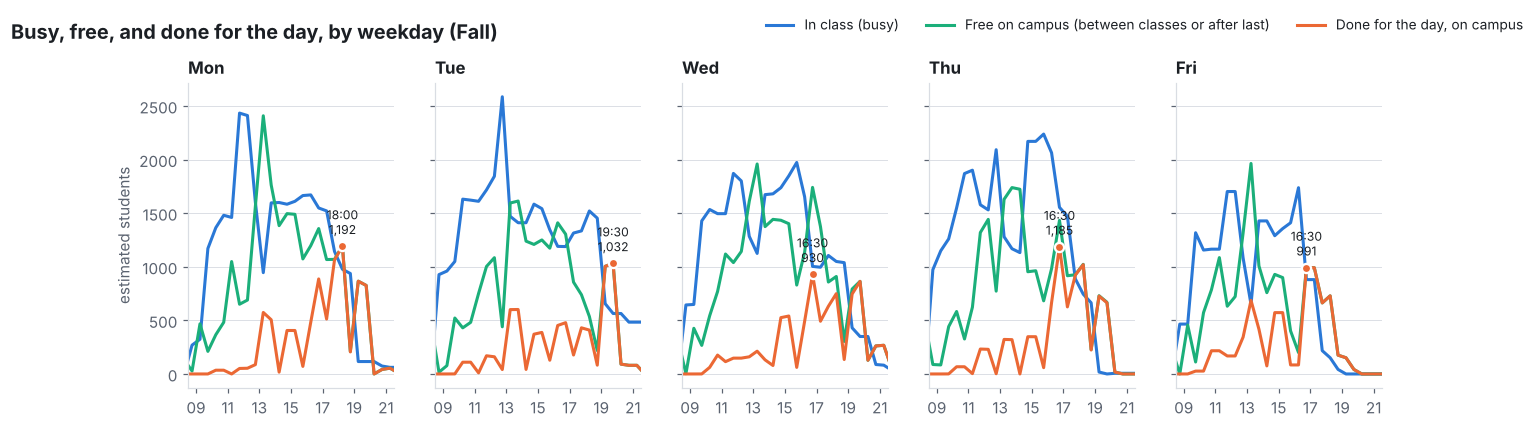

In [ ]:
x = np.arange(cm.N_SLOTS) + 0.5
fig, axes = plt.subplots(1, 5, figsize=(14, 3.6), sharey=True)
for d, (ax, day) in enumerate(zip(axes, cm.DAYS)):
    ax.plot(x, busy_p[d], color=BLUE, lw=2, label="In class (busy)")
    ax.plot(x, free_p[d], color="#1baf7a", lw=2, label="Free on campus (between classes or after last)")
    ax.plot(x, done_p[d], color=ORANGE, lw=2, label="Done for the day, on campus")
    k = int(np.argmax(done_p[d][6:24])) + 6   # peak 'done' between 11:00 and 20:00
    ax.scatter([x[k]], [done_p[d][k]], color=ORANGE, s=36, zorder=3, edgecolor="white", lw=1.5)
    ax.annotate(f"{cm.SLOT_LABELS[k]}\n{done_p[d][k]:,.0f}", (x[k], done_p[d][k]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8, color=INK)
    ax.set_title(day)
    ax.set_xticks([2, 6, 10, 14, 18, 22, 26], ["09", "11", "13", "15", "17", "19", "21"])
    ax.set_xlim(1, 27)
    ax.grid(axis="y", color=RULE, lw=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("estimated students")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3, bbox_to_anchor=(1, 1.08), fontsize=9)
fig.suptitle("Busy, free, and done for the day, by weekday (Fall)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
save(fig, "9_people_by_day"); plt.show()

### Ranked windows, in people

Half-hours from 11:00 to 19:30 ranked by the estimated number of students done for the day and still on campus. "Free on campus" adds the students between classes, who could drop in for part of an event. "Still in class" is the number busy in that half-hour.

In [ ]:
rows = []
for d, day in enumerate(cm.DAYS):
    for s in range(6, 24):
        end = cm.SLOT_LABELS[s + 1] if s + 1 < cm.N_SLOTS else "22:00"
        contrib = res.assign(v=[r.done[d, s] * r.students for _, r in res.iterrows()]).nlargest(3, "v")
        rows.append(dict(day=day, window=f"{cm.SLOT_LABELS[s]}–{end}",
                         done_for_day=done_p[d, s], free_on_campus=free_p[d, s], just_finished=last_p[d, s - 1],
                         still_in_class=busy_p[d, s],
                         biggest_groups=", ".join(f"{c} ({v:,.0f})" for c, v in zip(contrib.cohort, contrib.v))))
best_p = pd.DataFrame(rows).sort_values("done_for_day", ascending=False).head(12).reset_index(drop=True)
best_p.index += 1
best_p.style.format({"done_for_day": "{:,.0f}", "free_on_campus": "{:,.0f}", "just_finished": "{:,.0f}",
                     "still_in_class": "{:,.0f}"}).bar(
    subset=["done_for_day"], color="#fcd9c7", vmin=0)

,day,window,done_for_day,free_on_campus,just_finished,still_in_class,biggest_groups
1,Mon,18:00–18:30,"1,192","1,196","1,026",977,"CS (BSc Spec Hons) · Y1 (412), CS (BSc Spec Hons) · Y2 (186), Civil Eng · Y3 (118)"
2,Thu,16:30–17:00,"1,185","1,433",606,"1,554","CS (BSc Spec Hons) · Y1 (426), CS (BSc Spec Hons) · Y2 (190), 1st-year Engineering · Y1 (167)"
3,Mon,17:30–18:00,"1,065","1,069",39,"1,143","CS (BSc Spec Hons) · Y1 (412), CS (BSc Spec Hons) · Y2 (186), Software Eng · Y3 (107)"
4,Tue,19:30–20:00,"1,032","1,032",940,564,"1st-year Engineering · Y1 (528), CS (BSc Spec Hons) · Y2 (174), Software Eng · Y2 (92)"
5,Thu,18:00–18:30,"1,019","1,022",876,744,"CS (BSc Spec Hons) · Y2 (242), 1st-year Engineering · Y1 (140), Civil Eng · Y3 (118)"
6,Tue,19:00–19:30,"1,004","1,004",64,656,"1st-year Engineering · Y1 (528), CS (BSc Spec Hons) · Y2 (174), Software Eng · Y2 (87)"
7,Fri,16:30–17:00,991,991,0,880,"1st-year Engineering · Y1 (431), CS (BSc Spec Hons) · Y2 (315), Mechanical Eng · Y3 (80)"
8,Fri,17:00–17:30,991,991,991,880,"1st-year Engineering · Y1 (431), CS (BSc Spec Hons) · Y2 (315), Mechanical Eng · Y3 (80)"
9,Wed,16:30–17:00,930,"1,741",445,"1,003","1st-year Engineering · Y1 (386), CS (BSc Spec Hons) · Y2 (225), CS (BSc Spec Hons) · Y4 (135)"
10,Thu,17:30–18:00,923,926,46,888,"CS (BSc Spec Hons) · Y2 (242), 1st-year Engineering · Y1 (140), Software Eng · Y3 (107)"


### What if students only stay 30 minutes?

Everything above assumes students stay about **60 minutes** after their last class. Here is the same analysis if they leave after **30 minutes**. Each simulated student has the same schedule as before (same random seed); only the time they stay after their last class changes.

A shorter stay shrinks the "done for the day" crowd and makes timing tighter: an event has to start right as a release wave ends.

In [ ]:
S30 = cohort_stacks(30)
p30 = {k: S30[k].sum(0) for k in S30}
people_figure(S30, 30)

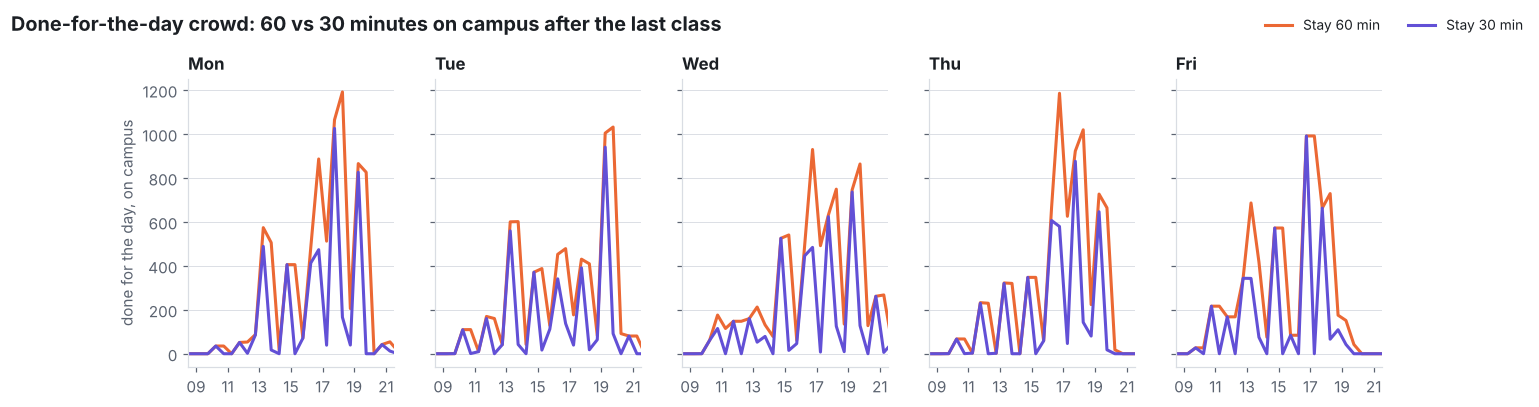

In [ ]:
# Done-for-the-day crowd, 60 vs 30 minutes, by weekday
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4), sharey=True)
for d, (ax, day) in enumerate(zip(axes, cm.DAYS)):
    ax.plot(x, done_p[d], color=ORANGE, lw=2, label="Stay 60 min")
    ax.plot(x, p30["done"][d], color="#6250d6", lw=2, label="Stay 30 min")
    ax.set_title(day)
    ax.set_xticks([2, 6, 10, 14, 18, 22, 26], ["09", "11", "13", "15", "17", "19", "21"])
    ax.set_xlim(1, 27)
    ax.grid(axis="y", color=RULE, lw=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("done for the day, on campus")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, bbox_to_anchor=(1, 1.08), fontsize=9)
fig.suptitle("Done-for-the-day crowd: 60 vs 30 minutes on campus after the last class", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.06)
save(fig, "11_done_60_vs_30"); plt.show()

In [ ]:
# Ranked windows if students only stay 30 minutes
rows = []
for d, day in enumerate(cm.DAYS):
    for s in range(6, 24):
        end = cm.SLOT_LABELS[s + 1] if s + 1 < cm.N_SLOTS else "22:00"
        rows.append(dict(day=day, window=f"{cm.SLOT_LABELS[s]}–{end}",
                         done_30min=p30["done"][d, s], done_60min=done_p[d, s],
                         free_on_campus_30min=p30["free"][d, s], still_in_class=p30["in_class"][d, s]))
best30 = pd.DataFrame(rows).sort_values("done_30min", ascending=False).head(12).reset_index(drop=True)
best30.index += 1
best30.style.format({c: "{:,.0f}" for c in best30.columns if c not in ("day", "window")}).bar(
    subset=["done_30min"], color="#ddd8f7", vmin=0)

,day,window,done_30min,done_60min,free_on_campus_30min,still_in_class
1,Mon,17:30–18:00,"1,026","1,065","1,030","1,143"
2,Fri,16:30–17:00,991,991,991,880
3,Tue,19:00–19:30,940,"1,004",940,656
4,Thu,17:30–18:00,876,923,879,888
5,Mon,19:00–19:30,826,866,826,116
6,Wed,19:00–19:30,736,745,783,430
7,Fri,17:30–18:00,663,663,663,217
8,Thu,19:00–19:30,646,727,649,18
9,Wed,17:30–18:00,624,631,850,"1,105"
10,Thu,16:00–16:30,606,665,924,"2,064"


**What changes with headcounts.** CS is about 40% of the students modelled, so CS schedules now drive the result much more than in section 7, where every cohort counted the same. The best window is where both a big release and a large program line up.

## 9. Caveats

* **Required courses only.** Electives, general education and breadth courses add more class time, so real students are on campus *more* than shown. Upper years are mostly electives, which is why they're thin.
* **Equal section weighting.** Without enrolment numbers, a 300-seat section and a 30-seat section are equally likely. Big sections are underweighted.
* **Headcounts are estimates by year.** OIPA reports students per program, not per year. Section 8 splits them using one university-wide retention rate and assumed losses; real program-level retention differs. Part-time students are counted as if full-time.
* **Behaviour is assumed.** Staying 60 (or 30) minutes after the last class is a guess; section 8 shows both, and `linger` in `cm.simulate_cohort` takes any value. Lecture attendance isn't modelled.
* **Last class means last *required* class.** An elective later in the day would push a real student's day end later, so real day-ends are somewhat later than shown, especially for upper years.
* **Coverage gaps.** Courses outside the Lassonde and Science timetables are invisible (section 3).
* **Keele only.** Markham-taught sections and programs are excluded. Students who take some courses at Markham (e.g. first-year engineering sections there) are modelled as if they took the Keele sections.

## Updating for a new term

1. Save the new timetable pages from Passport York (e.g. `FW2027LE.html`, `FW2027SC.html`).
2. `python src/parse_timetable.py FW2027LE.html le.csv` and the same for SC, then merge them (see "Rebuild from fresh sources" in the README).
3. Drop the new checklists in a folder and run `python src/parse_checklists.py checklists/ data/requirements_all.csv` (re-add the Data Science rows).
4. Re-run this notebook.